# 06 · Extensión: ¿ayuda la jerarquía?


Las 39 categorías de nivel 2 cuelgan de 6 categorías de nivel 1 (*natural sciences*, *engineering and
technology*...). Comparamos dos formas de clasificar:

- **Plano**: un único clasificador elige directamente entre las 39 clases (es el modelo del notebook 02).
- **Jerárquico**: en dos pasos.
  1. Un clasificador predice la categoría de nivel 1 (6 clases).
  2. Dentro de esa categoría, otro clasificador elige la subcategoría de nivel 2
     (por ejemplo, si el paso 1 dice *medical and health sciences*, el paso 2 solo elige entre
     *basic medicine*, *clinical medicine*, *health sciences*...).

**Argumentos a favor del jerárquico**: cada clasificador del paso 2 resuelve un problema más pequeño
y se especializa en distinguir categorías parecidas entre sí.
**Argumentos en contra**: si el paso 1 se equivoca, el paso 2 ya no puede acertar (*propagación del
error*), y cada clasificador del paso 2 tiene menos datos de entrenamiento.

Para que la comparación sea justa, los dos usan **la misma representación (TF-IDF) y la misma
configuración** de regresión logística elegida en el notebook 02: lo único que cambia es la estructura.

## 0. Preparación

En Colab, sube `proyectos_etiquetados.pkl` y `particion.csv` al panel Archivos. En local, coloca ambos junto al notebook o en las carpetas compartidas `data/` y `resultados/`. Instala las dependencias con `pip install pandas numpy scikit-learn nltk matplotlib` si no están disponibles. Ejecuta todas las celdas en orden.

La configuración se fijó en el notebook 02 con la validación de nivel 2. Este notebook vuelve a entrenar ambos clasificadores de referencia con esa configuración y el mismo preprocesamiento, así que se puede ejecutar sin los CSV generados en el 02.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score


from pathlib import Path

base_local = Path.cwd()
base_equipo = base_local.parent if base_local.name == "notebooks" else base_local
candidatas = (base_local, base_equipo / "data", base_equipo / "resultados", Path("/content"))

def entrada(nombre):
    for carpeta in candidatas:
        ruta = carpeta / nombre
        if ruta.is_file():
            return ruta
    raise FileNotFoundError(f"Falta {nombre}. Consulta la sección de preparación.")

resultados = base_equipo / "resultados"
figuras = base_equipo / "figuras"
for carpeta in (resultados, figuras):
    carpeta.mkdir(parents=True, exist_ok=True)
RUTA_RESULTADOS = str(resultados) + os.sep
RUTA_FIGURAS = str(figuras) + os.sep

NGRAM = (1, 1)
CLASS_WEIGHT = "balanced"
C = 10

In [2]:
import nltk
from nltk.tokenize import wordpunct_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

for paquete in ["stopwords", "wordnet"]:
    recurso = f"corpora/{paquete}"
    try:
        nltk.data.find(recurso)
    except LookupError:
        try:
            nltk.data.find(recurso + ".zip")
        except LookupError:
            nltk.download(paquete, quiet=True, raise_on_error=True)

stopwords_en = set(stopwords.words("english"))
wnl = WordNetLemmatizer()

def preparar_texto(texto):
    tokens = wordpunct_tokenize(texto.lower())
    tokens = [t for t in tokens if t.isalpha() and len(t) > 2 and t not in stopwords_en]
    return [wnl.lemmatize(t) for t in tokens]


datos = pd.read_pickle(entrada("proyectos_etiquetados.pkl"))
particion = pd.read_csv(entrada("particion.csv"))
datos = datos.merge(particion, on="projectID", how="outer", validate="one_to_one", indicator=True)
if not datos["_merge"].eq("both").all():
    raise ValueError("Los identificadores de los datos y de la partición no coinciden.")
if datos["conjunto"].value_counts().to_dict() != {"train": 22386, "val": 4798, "test": 4798}:
    raise ValueError("La partición no coincide con la partición común del equipo.")
if datos[["summary", "nivel1", "nivel2"]].isna().any().any():
    raise ValueError("Hay resúmenes o etiquetas ausentes.")
if datos.groupby("nivel2")["nivel1"].nunique().ne(1).any():
    raise ValueError("Una categoría de nivel 2 aparece bajo varias raíces.")
datos["texto_limpio"] = datos["summary"].map(lambda texto: " ".join(preparar_texto(texto)))
train = datos[datos["conjunto"] == "train"].sort_values("projectID").reset_index(drop=True)
val = datos[datos["conjunto"] == "val"].sort_values("projectID").reset_index(drop=True)
test = datos[datos["conjunto"] == "test"].sort_values("projectID").reset_index(drop=True)

# Cada categoría de nivel 2 cuelga de una única categoría de nivel 1
madre = datos.groupby("nivel2")["nivel1"].first().to_dict()
hijas = datos.groupby("nivel1")["nivel2"].unique().apply(sorted).to_dict()
for raiz, lista in hijas.items():
    print(f"{raiz}: {len(lista)} subcategorías")

agricultural sciences: 4 subcategorías
engineering and technology: 11 subcategorías
humanities: 5 subcategorías
medical and health sciences: 5 subcategorías
natural sciences: 6 subcategorías
social sciences: 8 subcategorías


In [3]:
# El mismo TF-IDF que en el notebook 02 (ajustado solo con train)
vectorizador = TfidfVectorizer(min_df=5, max_df=0.5, sublinear_tf=True, ngram_range=NGRAM)
X = {"train": vectorizador.fit_transform(train["texto_limpio"]),
     "val": vectorizador.transform(val["texto_limpio"]),
     "test": vectorizador.transform(test["texto_limpio"])}
conjuntos = {"train": train, "val": val, "test": test}

## 1. Clasificador plano

Reproducimos los clasificadores del notebook 02 en los niveles 1 y 2. Entrenamos exclusivamente con el conjunto de entrenamiento.

In [4]:
def entrenar(nivel):
    modelo = LogisticRegression(C=C, class_weight=CLASS_WEIGHT, max_iter=1000)
    modelo.fit(X["train"], train[nivel])
    return {
        n: conjuntos[n][["projectID", nivel]].rename(columns={nivel: "y_true"}).assign(
            y_pred=modelo.predict(X[n])
        )
        for n in ("val", "test")
    }

plano = entrenar("nivel2")
paso1 = entrenar("nivel1")
clases = sorted(train["nivel2"].unique())
if not datos["nivel2"].isin(clases).all():
    raise ValueError("Hay clases de nivel 2 ausentes del entrenamiento.")

## 2. Clasificador jerárquico

El primer paso usa el clasificador de nivel 1. El segundo paso entrena un clasificador por raíz con los proyectos de entrenamiento de esa raíz.

In [5]:
clasificadores_paso2 = {}
for raiz in hijas:
    filas = (train["nivel1"] == raiz).values
    clf = LogisticRegression(C=C, class_weight=CLASS_WEIGHT, max_iter=1000)
    clf.fit(X["train"][filas], train.loc[filas, "nivel2"])
    clasificadores_paso2[raiz] = clf
    print(f"{raiz}: entrenado con {filas.sum()} proyectos")

agricultural sciences: entrenado con 451 proyectos
engineering and technology: entrenado con 4639 proyectos
humanities: entrenado con 802 proyectos
medical and health sciences: entrenado con 3595 proyectos
natural sciences: entrenado con 8764 proyectos
social sciences: entrenado con 4135 proyectos


In [6]:
def predecir_jerarquico(X_conj, raices):
    """Para cada proyecto, usa el clasificador del paso 2 de la raíz indicada."""
    pred = np.empty(len(raices), dtype=object)
    for raiz, clf in clasificadores_paso2.items():
        filas = (np.asarray(raices) == raiz)
        if filas.any():
            pred[filas] = clf.predict(X_conj[filas])
    if pd.isna(pred).any():
        raise ValueError("Algún proyecto quedó sin predicción de nivel 2.")
    return pred

jerarquico = {}
oraculo = {}
for n in ["val", "test"]:
    df = conjuntos[n]
    # Jerárquico real: la raíz la decide el paso 1
    jerarquico[n] = pd.DataFrame({"projectID": df["projectID"], "y_true": df["nivel2"],
                                  "y_pred": predecir_jerarquico(X[n], paso1[n]["y_pred"].values)})
    jerarquico[n].to_csv(RUTA_RESULTADOS + f"jerarquico_nivel2_{n}.csv", index=False)
    # Diagnóstico: se evalúa el mismo segundo paso usando la raíz verdadera.
    oraculo[n] = pd.DataFrame({"y_true": df["nivel2"],
                               "y_pred": predecir_jerarquico(X[n], df["nivel1"].values)})

## 3. Comparación

Las decisiones (como el análisis de qué variante funciona mejor) las miramos primero en validación;
el test confirma el resultado y nos da la incertidumbre.

In [7]:
filas = []
for nombre, preds in [("plano", plano), ("jerárquico", jerarquico), ("jerárquico con raíz verdadera (oráculo)", oraculo)]:
    fila = {"modelo": nombre}
    for n in ["val", "test"]:
        fila[f"{n} accuracy"] = accuracy_score(preds[n]["y_true"], preds[n]["y_pred"])
        fila[f"{n} macro-F1"] = f1_score(preds[n]["y_true"], preds[n]["y_pred"], labels=clases, average="macro", zero_division=0)
    filas.append(fila)

comparacion = pd.DataFrame(filas).set_index("modelo").round(3)
comparacion.to_csv(RUTA_RESULTADOS + "extension_comparacion.csv")
comparacion

,val accuracy,val macro-F1,test accuracy,test macro-F1
modelo,,,,
plano,0.520,0.397,0.503,0.377
jerárquico,0.485,0.361,0.471,0.343
jerárquico con raíz verdadera (oráculo),0.721,0.598,0.706,0.566


In [8]:
# Precisión del paso 1: con qué frecuencia acierta la categoría de nivel 1
for n in ["val", "test"]:
    acierto_raiz = (paso1[n]["y_pred"].values == conjuntos[n]["nivel1"].values).mean()
    print(f"{n}: el paso 1 acierta la raíz en el {100 * acierto_raiz:.1f} % de los proyectos")

val: el paso 1 acierta la raíz en el 65.8 % de los proyectos
test: el paso 1 acierta la raíz en el 65.1 % de los proyectos


### 3.1. ¿Es la diferencia significativa?

Igual que en el notebook 05: **bootstrap emparejado** sobre el test. Remuestreamos los proyectos del
test 1.000 veces (los mismos para los dos modelos) y calculamos la diferencia de macro-F1. Si el
intervalo del 95 % contiene el 0, no podemos decir que un modelo sea mejor que el otro.

In [9]:
rng = np.random.default_rng(42)
y_true = test["nivel2"].values
y_plano = plano["test"]["y_pred"].values
y_jer = jerarquico["test"]["y_pred"].values

diferencias = []
for _ in range(1000):
    i = rng.integers(0, len(y_true), len(y_true))
    diferencias.append(f1_score(y_true[i], y_jer[i], labels=clases, average="macro", zero_division=0) - f1_score(y_true[i], y_plano[i], labels=clases, average="macro", zero_division=0))

ic = np.percentile(diferencias, [2.5, 97.5])
dif = f1_score(y_true, y_jer, labels=clases, average="macro", zero_division=0) - f1_score(y_true, y_plano, labels=clases, average="macro", zero_division=0)
print(f"Diferencia (jerárquico - plano) en macro-F1: {dif:+.3f}")
print(f"Intervalo del 95 %: [{ic[0]:+.3f}, {ic[1]:+.3f}]")
print("¿Significativa?", "sí" if (ic[0] > 0 or ic[1] < 0) else "no")
pd.DataFrame([{"delta_macro_f1": dif, "ic95_inferior": ic[0], "ic95_superior": ic[1],
               "remuestras": 1000, "semilla": 42}]).to_csv(
    resultados / "extension_bootstrap.csv", index=False
)

Diferencia (jerárquico - plano) en macro-F1: -0.035
Intervalo del 95 %: [-0.047, -0.021]
¿Significativa? sí


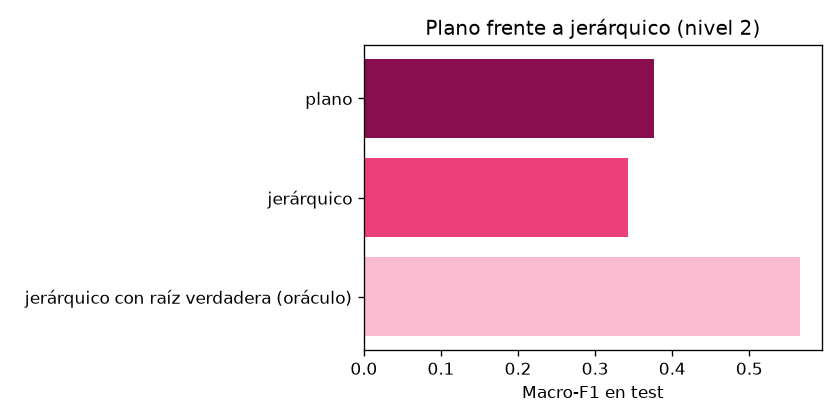

In [10]:
plt.figure(figsize=(7, 3.5))
valores = comparacion["test macro-F1"]
plt.barh(valores.index[::-1], valores.values[::-1], color=["#f8bbd0", "#ec407a", "#880e4f"])
plt.xlabel("Macro-F1 en test")
plt.title("Plano frente a jerárquico (nivel 2)")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "extension_comparacion.png", dpi=120)
plt.show()

## 4. ¿Dónde está la diferencia?

### 4.1. Tipo de error

Un error **dentro de la misma raíz** (confundir *basic medicine* con *clinical medicine*) es más
razonable que uno **entre raíces distintas** (confundir *basic medicine* con *sociology*).
El jerárquico debería cometer menos errores entre raíces... salvo los que vienen de que el paso 1 se equivoque.

In [11]:
filas = []
for nombre, preds in [("plano", plano), ("jerárquico", jerarquico)]:
    p = preds["test"]
    errores = p[p["y_true"] != p["y_pred"]]
    entre_raices = np.mean([madre[a] != madre[b] for a, b in zip(errores["y_true"], errores["y_pred"])])
    filas.append({"modelo": nombre, "errores": len(errores),
                  "% dentro de la misma raíz": round(100 * (1 - entre_raices), 1),
                  "% entre raíces distintas": round(100 * entre_raices, 1)})
tabla_errores = pd.DataFrame(filas).set_index("modelo")
tabla_errores.to_csv(resultados / "extension_errores.csv")
tabla_errores

,errores,% dentro de la misma raíz,% entre raíces distintas
modelo,,,
plano,2384,34.7,65.3
jerárquico,2537,34.1,65.9


In [12]:
# En el jerárquico, ¿cuántos errores vienen del paso 1?
errores_jer = jerarquico["test"]["y_true"] != jerarquico["test"]["y_pred"]
fallo_paso1 = paso1["test"]["y_pred"].values != test["nivel1"].values
print(f"Errores del jerárquico causados por el paso 1: {100 * (errores_jer & fallo_paso1).sum() / errores_jer.sum():.1f} %")

Errores del jerárquico causados por el paso 1: 65.9 %


### 4.2. ¿Qué clases ganan y cuáles pierden?

Diferencia de F1 por clase (jerárquico menos plano), en test.

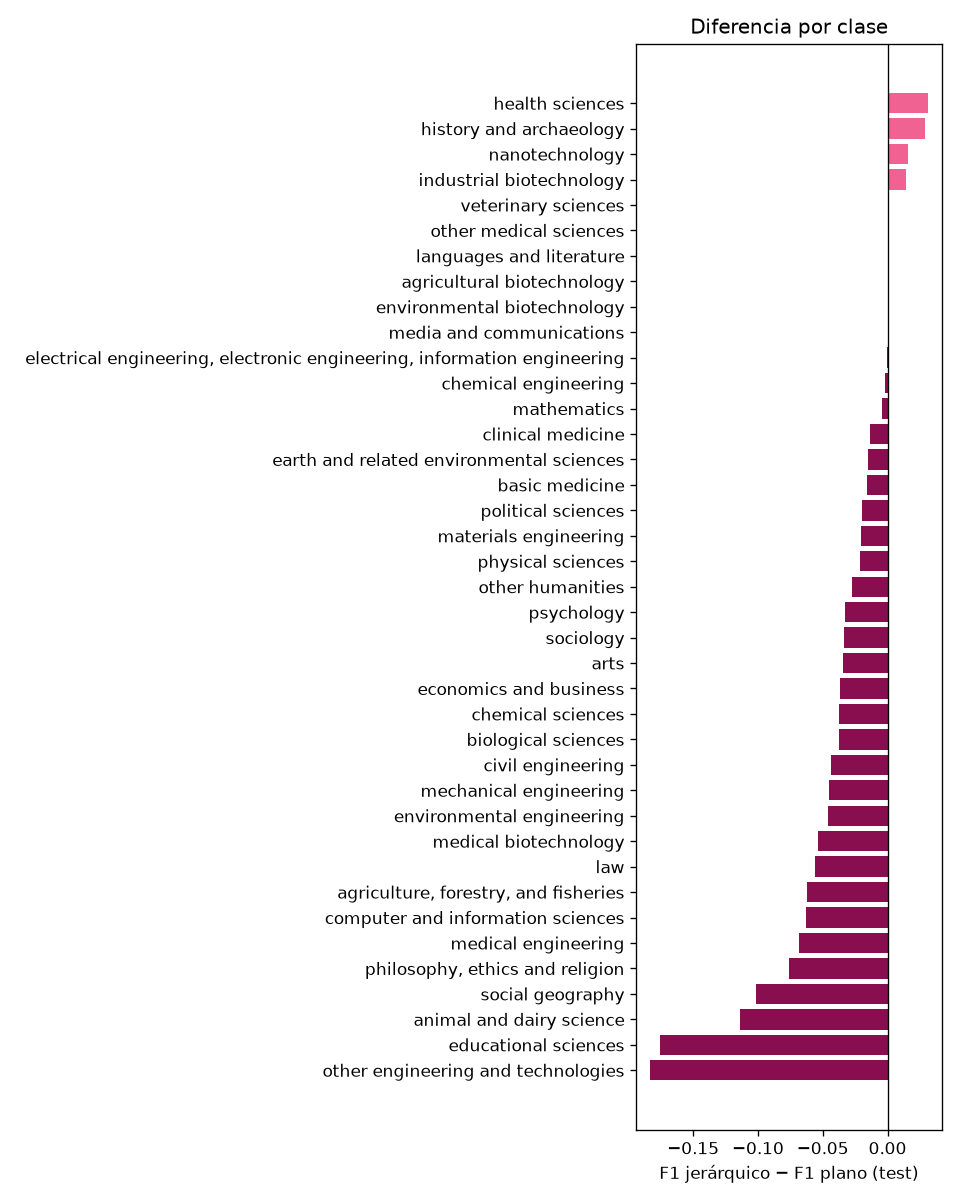

,F1 plano,F1 jerárquico,proyectos en train,diferencia
other engineering and technologies,0.319,0.136,155,-0.183
educational sciences,0.426,0.250,95,-0.176
animal and dairy science,0.327,0.213,92,-0.114
social geography,0.548,0.446,804,-0.102
"philosophy, ethics and religion",0.533,0.457,165,-0.076
medical engineering,0.318,0.250,91,-0.068
computer and information sciences,0.494,0.432,2038,-0.063
"agriculture, forestry, and fisheries",0.344,0.282,320,-0.062
law,0.341,0.286,103,-0.056
medical biotechnology,0.567,0.514,495,-0.054


In [13]:
clases = sorted(madre)
f1_plano = f1_score(plano["test"]["y_true"], plano["test"]["y_pred"], labels=clases, average=None, zero_division=0)
f1_jer = f1_score(jerarquico["test"]["y_true"], jerarquico["test"]["y_pred"], labels=clases, average=None, zero_division=0)
por_clase = pd.DataFrame({"F1 plano": f1_plano, "F1 jerárquico": f1_jer,
                          "proyectos en train": [(train["nivel2"] == c).sum() for c in clases]}, index=clases)
por_clase["diferencia"] = por_clase["F1 jerárquico"] - por_clase["F1 plano"]
por_clase = por_clase.sort_values("diferencia")

plt.figure(figsize=(8, 10))
colores = ["#880e4f" if d < 0 else "#f06292" for d in por_clase["diferencia"]]
plt.barh(por_clase.index, por_clase["diferencia"], color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("F1 jerárquico − F1 plano (test)")
plt.title("Diferencia por clase")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "extension_diferencia_por_clase.png", dpi=120)
plt.show()

por_clase.to_csv(resultados / "extension_f1_por_clase.csv", index_label="clase")
por_clase.round(3)

## 5. Conclusiones

La última celda genera un borrador para el informe con los resultados de la ejecución. La comparación principal es entre el plano y el jerárquico. El oráculo sirve para diagnosticar el efecto de elegir la raíz.

In [14]:
oraculo_f1 = f1_score(
    oraculo["test"]["y_true"], oraculo["test"]["y_pred"],
    labels=clases, average="macro", zero_division=0
)
jer_f1 = f1_score(y_true, y_jer, labels=clases, average="macro", zero_division=0)
if ic[0] > 0:
    lectura = "El intervalo favorece al clasificador jerárquico."
elif ic[1] < 0:
    lectura = "El intervalo favorece al clasificador plano."
else:
    lectura = "El intervalo incluye cero y la prueba no distingue el rendimiento de ambos modelos."

def extremos(serie):
    return ", ".join(f"{clase} ({valor:+.3f})" for clase, valor in serie.items()) or "ninguna"

delta_clases = por_clase["diferencia"]
ganan = extremos(delta_clases[delta_clases > 0].nlargest(3))
pierden = extremos(delta_clases[delta_clases < 0].nsmallest(3))
tabla = comparacion.rename_axis("Modelo").reset_index()
lineas = ["| " + " | ".join(tabla.columns) + " |",
          "| " + " | ".join(["---"] * len(tabla.columns)) + " |"]
for fila in tabla.itertuples(index=False, name=None):
    lineas.append("| " + " | ".join([fila[0], *(f"{v:.3f}" for v in fila[1:])]) + " |")

informe = f"""## Extensión jerárquica

Comparamos una regresión logística que predice directamente las categorías de nivel 2
con una cascada que predice la raíz y aplica una regresión logística específica de esa raíz.
Ambas usan TF-IDF de unigramas, ajustado solo con entrenamiento, y la configuración
seleccionada en validación en el notebook 02 (C=10 y pesos balanceados).
La extensión parte del notebook 06 compartido por el equipo y reutiliza el
preprocesamiento del notebook 02. Los clasificadores planos se volvieron a
entrenar para esta comparación. La ejecución se realizó con scikit-learn 1.9.1.

{chr(10).join(lineas)}

![Macro-F1 en test](../figuras/extension_comparacion.png)

En prueba, la diferencia de macro-F1 (jerárquico menos plano) fue {dif:+.3f}.
El intervalo percentil del 95 % con 1.000 remuestreos emparejados fue
[{ic[0]:+.3f}, {ic[1]:+.3f}]. {lectura}

La raíz se predijo correctamente en el {100 * (1 - fallo_paso1.mean()):.1f} % de los
proyectos de prueba. Cuando falla la raíz, el segundo clasificador no puede elegir
la subcategoría correcta. Este caso representa {fallo_paso1.sum()} de los
{errores_jer.sum()} errores del jerárquico. Con la raíz verdadera, su macro-F1
fue {oraculo_f1:.3f}, una diferencia de {oraculo_f1 - jer_f1:+.3f} respecto a la
cascada. Entre los errores del plano, el
{tabla_errores.loc["plano", "% entre raíces distintas"]:.1f} % cambió de raíz.
En la cascada, esa proporción fue del
{tabla_errores.loc["jerárquico", "% entre raíces distintas"]:.1f} %.

Mayores subidas de F1 por clase: {ganan}. Mayores bajadas: {pierden}.
Estas diferencias por clase son descriptivas y pueden fluctuar en clases con pocos ejemplos.

![Cambios de F1 por clase](../figuras/extension_diferencia_por_clase.png)

La comparación mide esta cascada con TF-IDF y regresión logística sobre una única
partición. Además, cada proyecto se evalúa contra una sola etiqueta EuroSciVoc,
aunque algunos proyectos pertenezcan a varias áreas.
"""
(resultados / "extension_informe.md").write_text(informe, encoding="utf-8")
print(informe)

## Extensión jerárquica

Comparamos una regresión logística que predice directamente las categorías de nivel 2
con una cascada que predice la raíz y aplica una regresión logística específica de esa raíz.
Ambas usan TF-IDF de unigramas, ajustado solo con entrenamiento, y la configuración
seleccionada en validación en el notebook 02 (C=10 y pesos balanceados).
La extensión parte del notebook 06 compartido por el equipo y reutiliza el
preprocesamiento del notebook 02. Los clasificadores planos se volvieron a
entrenar para esta comparación. La ejecución se realizó con scikit-learn 1.9.1.

| Modelo | val accuracy | val macro-F1 | test accuracy | test macro-F1 |
| --- | --- | --- | --- | --- |
| plano | 0.520 | 0.397 | 0.503 | 0.377 |
| jerárquico | 0.485 | 0.361 | 0.471 | 0.343 |
| jerárquico con raíz verdadera (oráculo) | 0.721 | 0.598 | 0.706 | 0.566 |

![Macro-F1 en test](../figuras/extension_comparacion.png)

En prueba, la diferencia de macro-F1 (jerárquico menos plano) fue -0.035.
El i